AI =  b(u) sii I0 = A_+ b(u) esto es lo que venimos resolviendo. NOTAR QUE I0 Y JO SON VECTORES

Usamos $\mathbf{C}^2 = \|\mathbf{J}_0\|_2 - \|\mathbf{I}_0\|_2 - 2i \times \mathbf{I}_0 \times \mathbf{J}_0$

# NO ME TOMA ALC

In [2]:
# from alc import norma, producto_interno, QR_con_GS
import numpy as np
import pandas as pd

EL archivo object_points me da las coordenadas de referencia es decir (U, V, W) y lo que me pide el ejercicio a) es que elija las coordenadas de la imagen convenientemente. Como se cuales son las de referencia entonces elijo los puntos que concuerdan con la referencia es decir el extremo exterior sup. izq., el extremo exterior sup. der., el extremo exterior inf. der. y el extremo exterior inf. izq.

/home/linux/librerias/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


(1232, 1640, 3)


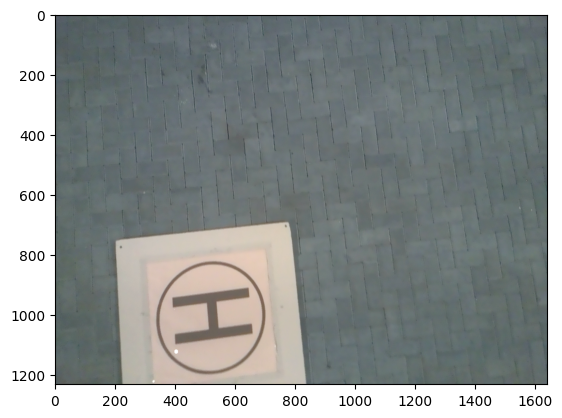

In [3]:
import cv2
import matplotlib.pyplot as plt

rgb = cv2.imread('../heli/row_00248.png')
plt.imshow(rgb)
print(rgb.shape)


Con esto ya tengo una referencia entonces jugamos un poco para ver que puntos puedo elegir, sigueindo el archivo chequeo_puntos_3d.ipynb y manteniendo el orden de object_points.csv

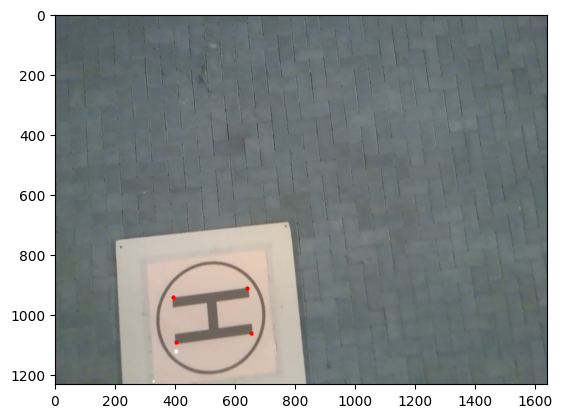

In [8]:
plt.imshow(rgb)

X = np.array([405, 395, 640, 655])
Y = np.array([1090, 940, 910, 1060])
plt.plot(X, Y, 'ro', markersize = 2)


In [ ]:
def calculoLambdaMu(I0, J0):
    # Podemos usar el metodo sqrt de numpy que esta permitido    
    C_2 = norma(J0, 2) - norma(I0, 2) - 2j * producto_interno(I0, J0)
    
    raiz = np.sqrt(C_2) # me da una sola raiz pero el ejercicio me pide las dos
    
    lammbda, mu = raiz
    
    return (lammbda, mu), (-lammbda, -mu)

Quiero encontrar I = I0 + lambda * n y J = J0 + mu *n
El I0, J0 me lo dan, el lambda y el mu los saco de la ecuacion de arriba y el n lo saco de An = 0 que es el mismo para los dos

Tengo que armar la matriz A. La matriz A la armo con M0 y los puntos puntos que yo elegi entiendo M0*Mi = ai y A=[a1, a2,..., ai]

# CAMBIAR ARROBA

# PREGUNTAR X0 E Y0

In [ ]:
def calcularSalidaPOSIT(Is, Js, fx, m0, M0):
    # Is y Js son vectores
    # M_0 = [X_0, Y_0, Z_0]
    
    norma_Is = norma(Is, 2)
    norma_Js = norma(Js, 2)
    
    Z_0 = fx / norma_Is
    
    i = Is / norma_Is
    j = Js / norma_Js
    
    # hace falta un vector ortogonal a i y j que ya son ortogonales entre si
    # para saber quien es k teniendo en cuenta los laboratorios
    # podemos pensar en el producto vectorial, pero no tenemos dicha funcion e implementarla
    # resulta engorroso porque no tememos funcion determinante. Hacerla directo con el producto
    # interno tambien es dificil porque no vimos como resolver un sistema lineal sin estar triangulado.
    # Entonces, uso QR_con_GS y me armo una matriz A con i, j y (1, 0, 0). Como i y j ya son ortogonales
    # en Q van a ser los mismos y la tercer columna va a ser nuestro i deseado. Justamente, la Q va a ser
    # R que nos estan pidiendo
    
    A = np.array([i,j,[1,0,0]]) 
    
    Q, R_de_Q = QR_con_GS(A)
    
    k = Q[2]
    R = Q
    
    x_0 = m0[0]
    y_0 = m0[1]
    
    
    X_0 = (Z_0 / fx) * x_0
    Y_0 = (Z_0 / fx) * y_0
    
    T = np.array([X_0, Y_0, Z_0])
    
    return i, j, k, Z_0, R, T 

$$K = \begin{bmatrix} f_x & \gamma & c_u \\ 0 & f_y & c_v \\ 0 & 0 & 1 \end{bmatrix}$$

In [ ]:
def evaluarPose(R, t, obj_vecs, img_vecs, K):

    puntos_camara = []
    
    for vecs in obj_vecs:
        punto_camara = R @ vecs + t # [X_i, Y_i, Z_i]
        # Quiere decir que quedo detras de la camara. Descartamos la solucion
        if punto_camara[2] <= 0: 
            return 0, None    
            
        puntos_camara.append(punto_camara)
     
    # Ahora queremos ver donde va a parar ese punto en el pixel (en la foto)
    # Las proyecciones en los pixeles van a ser K multiplicado cada punto.
    proyecciones = []
    for punto in puntos_camara:
        proyeccion = K @ punto # vector
        proyeccion = proyeccion[:2] / punto[2] # me saco el Z_i de encima
        proyecciones.append(proyeccion)
    
    # Una vez que tenemos la proyecciones, calculamos el RMS
    proyecciones = np.array(proyecciones) 
    img_vecs = np.array(img_vecs)
    
    rms = np.sqrt(np.mean((img_vecs - proyecciones)**2))

    return len(obj_vecs), rms
        
    